# 06 · Avaliação no instante do registro (v7)
**CRISP-DM:** Avaliação · **RQ1, RQ2, RQ3**

Para cada cenário, no instante do registro:
1. **Estado** do período [t − L, t) com L = 15 (principal), 30 e 60 min: Normal ou Residual;
2. **Indicador responsável** (4xx, 5xx, latência ou volume) quando Residual;
3. **Início**: expansão retroativa (0–15, 15–30, 30–60 min, depois de 1 h em 1 h até 4 h) até a primeira faixa Normal;
4. **Abrangência** (complementar): consumidor específico ou generalizado.

Método proposto: **regimes normais admissíveis** (limite = percentil 95). Cada cenário é decidido com o modelo do seu **mês de teste** (agosto ou setembro), ajustado só com dados anteriores. O histórico principal é de **3 meses**; o de **1 mês** é comparado na seção própria. "Média/alta" = intensidades média e alta (comparável à v2); a latência ×10 é relatada à parte.

Métricas: sensibilidade (incidentes com saída Residual), especificidade (controles com saída Normal), acurácia do indicador, acerto da zona de início, com **IC de Wilson (95%)**; comparação com os baselines pelo **teste de McNemar** (mesmos casos).

In [1]:
%run ./00_funcoes.ipynb

00_funcoes (v7) carregado · /home/wsl/gh/mestrado/claude9/v7


In [2]:
import pickle
import time
with open(RESULTADOS / "04_calibracao.pkl", "rb") as f:
    calib = pickle.load(f)
cenarios = pd.read_csv(RESULTADOS / "05_cenarios.csv", parse_dates=["t_registro"])
brutos = pd.read_parquet(RESULTADOS / "02_brutos_consolidados.parquet")
B = Brutos(brutos)

## Períodos de todos os cenários

In [3]:
t_ini = time.time()
linhas = []
for cen in cenarios.itertuples():
    linhas.extend(periodos_do_cenario(B, cen))
P = pd.DataFrame(linhas)
print(f"{len(P):,} períodos em {time.time() - t_ini:.0f} s")
# incidentes sem nenhum tráfego no intervalo degradado (lacunas nos dados) ficam fora das métricas
sem_traf = set(P.loc[P["sem_trafego"], "cenario"])
print(f"incidentes sem tráfego no intervalo degradado (excluídos): {len(sem_traf)}")
cenarios = cenarios[~cenarios["cenario"].isin(sem_traf)].reset_index(drop=True)
P = P[~P["cenario"].isin(sem_traf)].reset_index(drop=True)

109,440 períodos em 287 s
incidentes sem tráfego no intervalo degradado (excluídos): 3


## Decisão por método e faixa

In [4]:
cen_mes = cenarios.set_index("cenario")["mes"]


def decidir_mes(sub, nome, L, hist):
    """Decide cada período com a calibração do mês de teste do seu cenário."""
    partes = []
    chave = sub["cenario"].to_numpy() if "cenario" in sub.columns else sub.index.to_numpy()
    for mes, g in sub.groupby(cen_mes.reindex(chave).to_numpy()):
        res, ind, vz = decidir(g, calib[(nome, L, mes, hist)])
        partes.append(pd.DataFrame({"residual": res, "indicador": ind.to_numpy()}, index=g.index).join(vz.add_prefix("vz_")))
    return pd.concat(partes).reindex(sub.index)


dec = {}
for hist in HISTORICOS:
    for nome in METODOS:
        for L in FAIXAS_L:
            sub = P[(P["periodo"] == "L") & (P["id_periodo"] == L)].set_index("cenario")
            dec[(nome, L, hist)] = decidir_mes(sub, nome, L, hist)[["residual", "indicador"]]

# bandas da expansão retroativa (método proposto, histórico principal), cada uma com o limite do seu tamanho
bandas = P[P["periodo"] == "banda"].copy()
bandas["L"] = bandas["hi"] - bandas["lo"]
bandas["residual"] = False
for L in FAIXAS_L:
    m = (bandas["L"] == L).to_numpy()
    bandas.loc[m, "residual"] = decidir_mes(bandas[m], PROPOSTO, L, HIST_PRINCIPAL)["residual"].to_numpy()
res_bandas = bandas.pivot(index="cenario", columns="id_periodo", values="residual")
inicio = pd.DataFrame([estimar_inicio(list(v)) for v in res_bandas.to_numpy()], index=res_bandas.index,
                      columns=["estado_bandas", "zona_lo", "zona_hi"])


def tabela(nome, L, hist):
    t = cenarios.set_index("cenario").join(dec[(nome, L, hist)])
    t["esperado"] = t["motivo"].map(lambda m: MOTIVOS[m][0] if isinstance(m, str) else None)
    t["abr_esperada"] = t["motivo"].map(lambda m: MOTIVOS[m][1] if isinstance(m, str) else None)
    t["acerto_estado"] = np.where(t["tipo"] == "incidente", t["residual"], ~t["residual"])
    return t


T_all = {(n, L, h): tabela(n, L, h) for n in METODOS for L in FAIXAS_L for h in HISTORICOS}
T = {(n, L): T_all[(n, L, HIST_PRINCIPAL)] for n in METODOS for L in FAIXAS_L}  # histórico principal (3 meses)
inc = lambda t: t[t["tipo"] == "incidente"]
ctl = lambda t: t[t["tipo"] == "controle"]

## RQ1 · Estado no instante do registro

In [5]:
linhas = []
for (n, L), t in T.items():
    i, c = inc(t), ctl(t)
    i_mf = i[i["intensidade"].isin(["media", "alta"])]
    linhas.append(dict(metodo=n, L=L,
                       sensibilidade=fmt_ic(int(i["residual"].sum()), len(i)),
                       sens_media_alta=fmt_ic(int(i_mf["residual"].sum()), len(i_mf)),
                       especificidade=fmt_ic(int((~c["residual"]).sum()), len(c)),
                       sens=i["residual"].mean(), sens_ma=i_mf["residual"].mean(), espec=(~c["residual"]).mean()))
resumo = pd.DataFrame(linhas)
resumo[["metodo", "L", "sensibilidade", "sens_media_alta", "especificidade"]]

,metodo,L,sensibilidade,sens_media_alta,especificidade
0,Regimes normais (proposto),15,53.9% [52.7%; 55.2%],58.6% [57.1%; 60.2%],92.5% [91.8%; 93.1%]
1,Regimes normais (proposto),30,51.8% [50.6%; 53.1%],56.9% [55.3%; 58.5%],93.1% [92.4%; 93.7%]
2,Regimes normais (proposto),60,46.7% [45.4%; 47.9%],52.1% [50.5%; 53.7%],93.3% [92.6%; 93.9%]
3,Perfil por contexto,15,61.7% [60.5%; 62.9%],66.9% [65.3%; 68.3%],88.7% [87.9%; 89.5%]
4,Perfil por contexto,30,59.7% [58.5%; 61.0%],65.4% [63.9%; 66.9%],89.7% [88.9%; 90.4%]
5,Perfil por contexto,60,55.6% [54.3%; 56.8%],61.7% [60.1%; 63.2%],88.5% [87.6%; 89.2%]
6,Regimes sem contexto,15,44.0% [42.7%; 45.2%],48.4% [46.8%; 50.0%],95.6% [95.0%; 96.0%]
7,Regimes sem contexto,30,41.8% [40.5%; 43.0%],46.4% [44.8%; 48.0%],95.9% [95.3%; 96.3%]
8,Regimes sem contexto,60,37.0% [35.8%; 38.2%],41.6% [40.0%; 43.2%],96.4% [95.9%; 96.9%]
9,z-score global,15,58.8% [57.5%; 60.0%],63.2% [61.6%; 64.7%],91.4% [90.7%; 92.1%]


### Comparação com os baselines (McNemar, mesmos casos)

In [6]:
mc = []
for L in FAIXAS_L:
    a = T[(PROPOSTO, L)]["acerto_estado"]
    for b in METODOS:
        if b == PROPOSTO:
            continue
        n01, n10, p = mcnemar(a, T[(b, L)].loc[a.index, "acerto_estado"])
        mc.append(dict(L=L, baseline=b, so_proposto_acerta=n01, so_baseline_acerta=n10, p=p))
mc = pd.DataFrame(mc)
mc

,L,baseline,so_proposto_acerta,so_baseline_acerta,p
0,15,Perfil por contexto,658,898,1.274507e-09
1,15,Regimes sem contexto,665,247,5.995790e-45
2,15,z-score global,537,767,2.048760e-10
3,15,Semana anterior,648,883,2.075490e-09
4,30,Perfil por contexto,614,887,1.926282e-12
5,30,Regimes sem contexto,670,229,7.904468e-51
6,30,z-score global,507,747,1.293185e-11
7,30,Semana anterior,615,876,1.475664e-11
8,60,Perfil por contexto,692,938,1.204982e-09
9,60,Regimes sem contexto,638,241,4.020002e-42


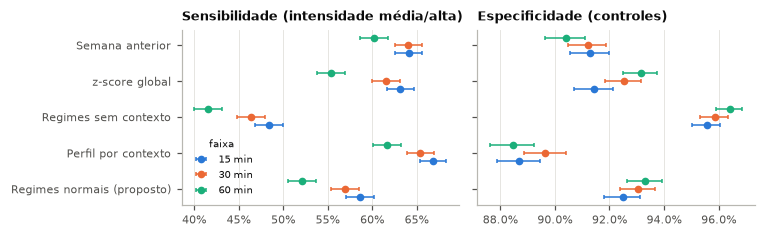

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.2), sharey=True)
metodos = list(METODOS)
for ax, (col, titulo) in zip(axes, [("sens_ma", "Sensibilidade (intensidade média/alta)"), ("espec", "Especificidade (controles)")]):
    for j, L in enumerate(FAIXAS_L):
        for i, n in enumerate(metodos):
            t = T[(n, L)]
            base = inc(t)[inc(t)["intensidade"].isin(["media", "alta"])] if col == "sens_ma" else ctl(t)
            k = int(base["residual"].sum()) if col == "sens_ma" else int((~base["residual"]).sum())
            p = k / len(base)
            lo, hi = wilson(k, len(base))
            y = i + (j - 1) * 0.22
            ax.errorbar(p, y, xerr=[[p - lo], [hi - p]], fmt="o", ms=4, color=CORES[j], ecolor=CORES[j], lw=1,
                        capsize=1.5, label=f"{L} min" if i == 0 else None)
    ax.set_yticks(range(len(metodos)))
    ax.set_yticklabels(metodos)
    ax.invert_yaxis()
    ax.set_title(titulo, loc="left")
    ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0 if col == "sens_ma" else 1))
    ax.grid(axis="y", visible=False)
axes[0].legend(title="faixa", loc="lower left", fontsize=6.5, title_fontsize=6.5)
fig.tight_layout()
salvar(fig, "fig_metodos")
plt.show()

### Sensibilidade por motivo e intensidade (método proposto, 15 min)

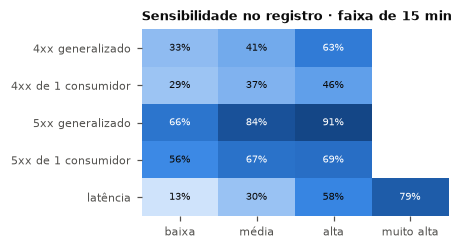

,baixa,média,alta,muito alta
motivo,,,,
4xx generalizado,0.330,0.413,0.626,NaN
4xx de 1 consumidor,0.293,0.375,0.463,NaN
5xx generalizado,0.658,0.842,0.905,NaN
5xx de 1 consumidor,0.561,0.674,0.689,NaN
latência,0.134,0.297,0.579,0.787


In [8]:
t15 = inc(T[(PROPOSTO, L_PRINCIPAL)])
sm = t15.groupby(["motivo", "intensidade"])["residual"].mean().unstack()[INTENSIDADES]
sm.index = sm.index.map(NOMES_MOTIVO)
sm = sm.loc[[NOMES_MOTIVO[m] for m in MOTIVOS]]
sm.columns = ["baixa", "média", "alta", "muito alta"]
fig, ax = plt.subplots(figsize=(3.6, 2.2))
heatmap(ax, sm)
ax.set_title("Sensibilidade no registro · faixa de 15 min", loc="left")
salvar(fig, "fig_sens_motivo")
plt.show()
sm.round(3)

## Ponto de operação: 1%, 2% e 5% de alarmes no histórico
Mesmos limites-base (percentil 95 por indicador), variando o multiplicador c para metas de 1%, 2%, 5% e 10% de alarmes. O ponto adotado é c = 1. Histórico de 3 meses.

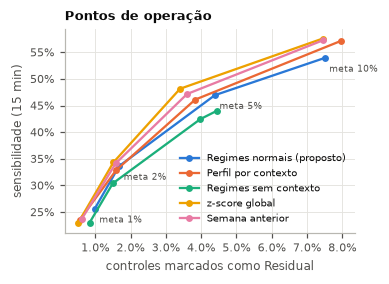

,metodo,meta,sensibilidade,sens_media_alta,especificidade,sens_latencia,acuracia_indicador
0,Regimes normais (proposto),0.01,0.256,0.347,0.990,0.028,0.977
1,Regimes normais (proposto),0.02,0.336,0.411,0.983,0.143,0.970
2,Regimes normais (proposto),0.05,0.469,0.521,0.956,0.335,0.937
3,Regimes normais (proposto),0.10,0.539,0.586,0.925,0.449,0.904
4,Perfil por contexto,0.01,0.235,0.322,0.994,0.037,0.983
5,Perfil por contexto,0.02,0.329,0.417,0.984,0.147,0.977
6,Perfil por contexto,0.05,0.461,0.537,0.962,0.357,0.967
7,Perfil por contexto,0.10,0.572,0.627,0.920,0.533,0.945
8,Regimes sem contexto,0.01,0.230,0.301,0.992,0.041,0.969
9,Regimes sem contexto,0.02,0.304,0.365,0.985,0.137,0.954


In [9]:
p15 = P[(P["periodo"] == "L") & (P["id_periodo"] == L_PRINCIPAL)].set_index("cenario").join(cenarios.set_index("cenario")[["tipo", "motivo", "intensidade", "mes"]])
curva = []
for nome in METODOS:
    for meta in METAS_CURVA:
        partes = []
        for mes, g in p15.groupby("mes"):
            cal = calib[(nome, L_PRINCIPAL, mes, HIST_PRINCIPAL)]
            razao = z_direcional(cal["modelo"].z(g, cal["base"])) / cal["base"].reindex(g["recurso"]).to_numpy()
            c = max(1.0, float(np.quantile(cal["razao_cal"], 1 - meta)))
            partes.append(pd.DataFrame({"res": razao.max(axis=1) > c, "ind": razao.idxmax(axis=1).map(INDICADOR)}, index=g.index))
        d = pd.concat(partes).join(p15[["tipo", "motivo", "intensidade"]])
        inc_ = d["tipo"] == "incidente"
        det = d[inc_ & d["res"]]
        curva.append(dict(metodo=nome, meta=meta, sensibilidade=d.loc[inc_, "res"].mean(),
                          sens_media_alta=d.loc[inc_ & d["intensidade"].isin(["media", "alta"]), "res"].mean(),
                          especificidade=(~d.loc[~inc_, "res"]).mean(),
                          sens_latencia=d.loc[inc_ & (d["motivo"] == "latencia"), "res"].mean(),
                          acuracia_indicador=(det["ind"] == det["motivo"].map(lambda m: MOTIVOS[m][0])).mean()))
curva = pd.DataFrame(curva)
fig, ax = plt.subplots(figsize=(3.4, 2.4))
for i, nome in enumerate(METODOS):
    c_ = curva[curva["metodo"] == nome]
    ax.plot(1 - c_["especificidade"], c_["sensibilidade"], marker="o", ms=3.5, color=CORES[i], label=nome)
    for _, r_ in c_.iterrows():
        if nome == PROPOSTO:
            ax.annotate(f"meta {r_['meta']:.0%}", (1 - r_["especificidade"], r_["sensibilidade"]), fontsize=6,
                        xytext=(3, -9), textcoords="offset points", color=TXT2)
ax.set_xlabel("controles marcados como Residual")
ax.set_ylabel("sensibilidade (15 min)")
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=1))
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0))
ax.legend(loc="lower right", fontsize=6.3)
ax.set_title("Pontos de operação", loc="left")
salvar(fig, "fig_curva_operacao")
plt.show()
curva.round(3)

## RQ3 · Tamanho da faixa × atraso do registro

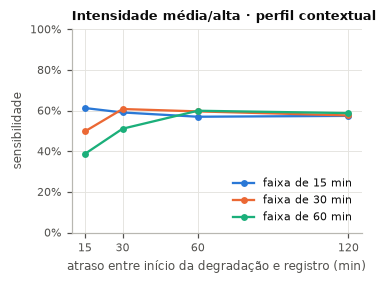

,15,30,60
atraso,,,
15.0,0.558,0.432,0.334
30.0,0.547,0.563,0.440
60.0,0.530,0.547,0.555
120.0,0.522,0.531,0.538


,15,30,60
atraso,,,
15.0,0.612,0.497,0.387
30.0,0.591,0.607,0.511
60.0,0.569,0.596,0.599
120.0,0.574,0.576,0.587


In [10]:
sa = pd.DataFrame({L: inc(T[(PROPOSTO, L)]).groupby("atraso")["residual"].mean() for L in FAIXAS_L})
sa_ma = pd.DataFrame({L: inc(T[(PROPOSTO, L)]).query("intensidade in ['media', 'alta']").groupby("atraso")["residual"].mean()
                      for L in FAIXAS_L})
fig, ax = plt.subplots(figsize=(3.4, 2.4))
for j, L in enumerate(FAIXAS_L):
    ax.plot(sa_ma.index, sa_ma[L], marker="o", ms=3.5, color=CORES[j], label=f"faixa de {L} min")
ax.set_xticks(ATRASOS)
ax.set_xlabel("atraso entre início da degradação e registro (min)")
ax.set_ylabel("sensibilidade")
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0))
ax.legend(loc="lower right")
ax.set_title("Intensidade média/alta · perfil contextual", loc="left")
salvar(fig, "fig_sens_atraso")
plt.show()
display(sa.round(3))
sa_ma.round(3)

## RQ2 · Indicador responsável (método proposto)

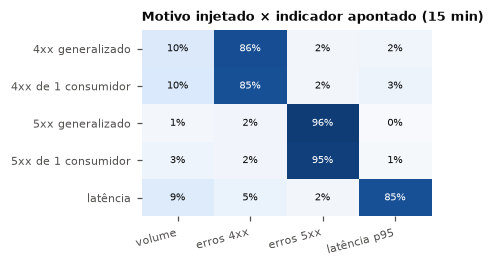

indicador,volume,erros 4xx,erros 5xx,latência p95
motivo,,,,
4xx generalizado,0.096,0.860,0.019,0.025
4xx de 1 consumidor,0.100,0.848,0.019,0.033
5xx generalizado,0.014,0.020,0.964,0.002
5xx de 1 consumidor,0.027,0.021,0.945,0.007
latência,0.089,0.045,0.016,0.849


15    90.4% [89.4%; 91.4%]
30    91.5% [90.5%; 92.4%]
60    91.1% [90.0%; 92.1%]
Name: acurácia do indicador, dtype: str

In [11]:
det15 = t15[t15["residual"]]
conf = pd.crosstab(det15["motivo"].map(NOMES_MOTIVO), det15["indicador"], normalize="index")
conf = conf.reindex(index=[NOMES_MOTIVO[m] for m in MOTIVOS], columns=list(INDICADOR.values()), fill_value=0)
acc_ind = {L: (inc(T[(PROPOSTO, L)]).query("residual")["indicador"] == inc(T[(PROPOSTO, L)]).query("residual")["esperado"]) for L in FAIXAS_L}
acc_ind_tab = pd.Series({L: fmt_ic(int(v.sum()), len(v)) for L, v in acc_ind.items()}, name="acurácia do indicador")
fig, ax = plt.subplots(figsize=(3.4, 2.2))
heatmap(ax, conf)
ax.set_xticklabels(conf.columns, rotation=15, ha="right")
ax.set_title("Motivo injetado × indicador apontado (15 min)", loc="left")
salvar(fig, "fig_confusao_indicador")
plt.show()
display(conf.round(3))
acc_ind_tab

### Abrangência (complementar)

In [12]:
Pidx = P[(P["periodo"] == "L") & (P["id_periodo"] == L_PRINCIPAL)].set_index("cenario")
d_ok = det15[det15["indicador"] == det15["esperado"]]
d_ok = d_ok[d_ok["motivo"].str.startswith(("4xx", "5xx"))]
abr = pd.Series({c: abrangencia(Pidx.loc[c], d_ok.loc[c, "indicador"]) for c in d_ok.index})
d_ok = d_ok.assign(abr_prevista=abr)
tab_abr = pd.crosstab(d_ok["motivo"].map(NOMES_MOTIVO), d_ok["abr_prevista"], normalize="index").round(2)
acc_abr = (d_ok["abr_prevista"] == d_ok["abr_esperada"])
display(tab_abr)
print("acurácia da abrangência:", fmt_ic(int(acc_abr.sum()), len(acc_abr)))

abr_prevista,consumidor específico,generalizado,indeterminada
motivo,,,
4xx de 1 consumidor,0.57,0.31,0.12
4xx generalizado,0.02,0.88,0.11
5xx de 1 consumidor,0.66,0.21,0.12
5xx generalizado,0.02,0.87,0.11


acurácia da abrangência: 76.5% [74.8%; 78.2%]


## RQ2 · Início estimado (expansão retroativa, método proposto)
Zona estimada: entre o início da última faixa residual e o fim da primeira faixa normal (em minutos antes do registro). Acerto: o início real está dentro da zona.

In [13]:
ti = inc(T[(PROPOSTO, L_PRINCIPAL)]).join(inicio)
ti = ti[ti["estado_bandas"] == "Residual"]
ti["acerto_inicio"] = (ti["atraso"] >= ti["zona_lo"]) & (ti["zona_hi"].isna() | (ti["atraso"] <= ti["zona_hi"]))
acerto_inicio = ti.groupby("atraso")["acerto_inicio"].agg(["mean", "size"])
acerto_inicio["IC 95%"] = [fmt_ic(int(round(m * n)), n) for m, n in acerto_inicio.to_numpy()]
print("acerto geral da zona de início:", fmt_ic(int(ti["acerto_inicio"].sum()), len(ti)))
zonas = ti.assign(zona=ti["zona_lo"].astype(int).astype(str) + "–" + ti["zona_hi"].fillna(-1).astype(int).astype(str).replace("-1", "mais")
                  ).groupby(["atraso", "zona"]).size().unstack(fill_value=0)
display(acerto_inicio)
zonas

acerto geral da zona de início: 89.0% [87.9%; 90.1%]


,mean,size,IC 95%
atraso,,,
15.0,0.961039,847,96.1% [94.6%; 97.2%]
30.0,0.980769,832,98.1% [96.9%; 98.8%]
60.0,0.828571,805,82.9% [80.1%; 85.3%]
120.0,0.783102,793,78.3% [75.3%; 81.0%]


zona,0–30,120–240,15–60,180–mais,30–120,60–180
atraso,,,,,,
15.0,781,3,33,2,19,9
30.0,123,3,650,1,43,12
60.0,117,11,53,10,586,28
120.0,106,37,55,11,43,541


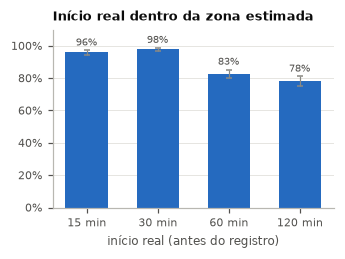

In [14]:
fig, ax = plt.subplots(figsize=(3.3, 2.1))
ax.bar(range(len(ATRASOS)), acerto_inicio["mean"], color=AZUL[4], width=0.6)
for i, (m, n) in enumerate(acerto_inicio[["mean", "size"]].to_numpy()):
    lo, hi = wilson(int(round(m * n)), n)
    ax.errorbar(i, m, yerr=[[m - lo], [hi - m]], color=TXT3, capsize=2, lw=0.8)
    ax.text(i, hi + 0.03, f"{m:.0%}", ha="center", fontsize=6.8, color=TXT2)
ax.set_xticks(range(len(ATRASOS)))
ax.set_xticklabels([f"{a} min" for a in ATRASOS])
ax.set_xlabel("início real (antes do registro)")
ax.set_ylim(0, 1.1)
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0))
ax.set_title("Início real dentro da zona estimada", loc="left")
ax.grid(axis="x", visible=False)
salvar(fig, "fig_inicio")
plt.show()

### Exemplo de expansão retroativa

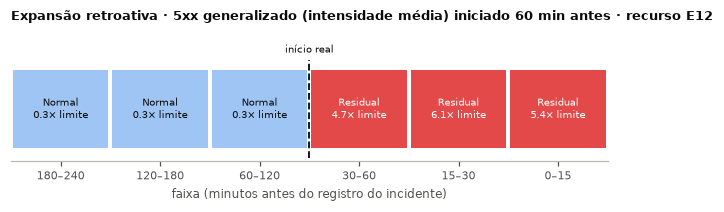

In [15]:
cand = ti[(ti["motivo"] == "5xx_geral") & (ti["atraso"] == 60) & ti["acerto_inicio"] & (ti["intensidade"] == "media")]
if cand.empty:
    cand = ti[ti["acerto_inicio"] & (ti["atraso"] >= 30)]
c_ex = cand.index[0]
b_ex = bandas[bandas["cenario"] == c_ex].sort_values("id_periodo")
cal_by_L = {L: calib[(PROPOSTO, L, cen_mes[c_ex], HIST_PRINCIPAL)] for L in FAIXAS_L}
vezes_ex = [decidir(b_ex[b_ex["id_periodo"] == i], cal_by_L[int(b_ex.loc[b_ex["id_periodo"] == i, "L"].iloc[0])])[2].max(axis=1).iloc[0]
            for i in b_ex["id_periodo"]]
fig, ax = plt.subplots(figsize=(7.0, 1.55))
nb = len(BANDAS)
atraso_ex = int(cenarios.set_index("cenario").loc[c_ex, "atraso"])
for k, ((lo, hi), res_b, v) in enumerate(zip(BANDAS, b_ex["residual"], vezes_ex)):
    x = nb - 1 - k  # mais antiga à esquerda, registro à direita
    ax.barh(0, 0.96, left=x + 0.02, height=0.6, color=CORES[7] if res_b else AZUL[1])
    ax.text(x + 0.5, 0, f"{'Residual' if res_b else 'Normal'}\n{v:.1f}× limite", ha="center", va="center", fontsize=6.5,
            color="white" if res_b else TXT1)
    if lo < atraso_ex <= hi:  # posição do início real dentro da faixa
        xr = x + 1 - (atraso_ex - lo) / (hi - lo)
        ax.plot([xr, xr], [-0.38, 0.38], color=TXT1, lw=1.2, ls="--")
        ax.text(xr, 0.42, "início real", fontsize=6.5, ha="center", va="bottom")
ax.set_xlim(0, nb)
ax.set_ylim(-0.4, 0.62)
ax.set_xticks([nb - 0.5 - k for k in range(nb)])
ax.set_xticklabels([f"{lo}–{hi}" for lo, hi in BANDAS])
ax.set_xlabel("faixa (minutos antes do registro do incidente)")
ax.set_yticks([])
ax.grid(False)
ax.spines["left"].set_visible(False)
ax.set_title(f"Expansão retroativa · 5xx generalizado (intensidade média) iniciado {atraso_ex} min antes · recurso "
             f"{rot(cenarios.set_index('cenario').loc[c_ex, 'recurso'])}", loc="left")
salvar(fig, "fig_expansao_exemplo")
plt.show()

## Por recurso (método proposto, 15 min)

In [16]:
por_rec = pd.DataFrame({
    "sensibilidade": inc(T[(PROPOSTO, 15)]).groupby("recurso")["residual"].mean(),
    "sens. média/alta": inc(T[(PROPOSTO, 15)]).query("intensidade in ['media', 'alta']").groupby("recurso")["residual"].mean(),
    "especificidade": (~ctl(T[(PROPOSTO, 15)])["residual"]).groupby(ctl(T[(PROPOSTO, 15)])["recurso"]).mean(),
    "acurácia indicador": det15.assign(ok=det15["indicador"] == det15["esperado"]).groupby("recurso")["ok"].mean(),
})
por_rec.index = por_rec.index.map(rot)
por_rec = por_rec.sort_index()
por_rec.round(2)

,sensibilidade,sens. média/alta,especificidade,acurácia indicador
recurso,,,,
E01,0.68,0.73,0.93,0.96
E02,0.34,0.38,0.85,0.60
E03,0.31,0.36,0.95,0.86
E04,0.60,0.66,0.88,0.83
E05,0.78,0.82,0.92,0.97
E06,0.12,0.09,0.94,0.74
E07,0.55,0.62,0.96,0.97
E08,0.57,0.63,0.93,0.91
E09,0.68,0.73,0.93,0.91


## Histórico de 3 meses × 1 mês (método proposto)
Mesmos cenários, modelo ajustado com os 3 meses ou só com o mês anterior ao teste. McNemar sobre os acertos de estado.

In [17]:
hist_tab = []
for L in FAIXAS_L:
    for h in HISTORICOS:
        t = T_all[(PROPOSTO, L, h)]
        i, c = inc(t), ctl(t)
        ima = i[i["intensidade"].isin(["media", "alta"])]
        det = i[i["residual"]]
        hist_tab.append(dict(L=L, historico=h, sensibilidade=fmt_ic(int(i["residual"].sum()), len(i)),
                             sens_media_alta=fmt_ic(int(ima["residual"].sum()), len(ima)),
                             especificidade=fmt_ic(int((~c["residual"]).sum()), len(c)),
                             acuracia_indicador=f"{(det['indicador'] == det['esperado']).mean():.1%}",
                             sens=i["residual"].mean(), sens_ma=ima["residual"].mean(), espec=(~c["residual"]).mean()))
    a3, a1 = T_all[(PROPOSTO, L, "3m")]["acerto_estado"], T_all[(PROPOSTO, L, "1m")]["acerto_estado"]
    n01, n10, pv = mcnemar(a3, a1.loc[a3.index])
    hist_tab[-1]["mcnemar_3m_vs_1m"] = f"só 3m acerta {n01} · só 1m acerta {n10} · p = {pv:.3g}"
hist_tab = pd.DataFrame(hist_tab)
display(hist_tab.drop(columns=["sens", "sens_ma", "espec"]))
por_mes_hist = pd.concat({h: T_all[(PROPOSTO, 15, h)].groupby(["mes", "tipo"])["acerto_estado"].mean().unstack() for h in HISTORICOS}, axis=1)
por_mes_hist.columns = [f"{h} · {'sensibilidade' if t == 'incidente' else 'especificidade'}" for h, t in por_mes_hist.columns]
por_mes_hist.round(3)

,L,historico,sensibilidade,sens_media_alta,especificidade,acuracia_indicador,mcnemar_3m_vs_1m
0,15,3m,53.9% [52.7%; 55.2%],58.6% [57.1%; 60.2%],92.5% [91.8%; 93.1%],90.4%,NaN
1,15,1m,60.7% [59.5%; 61.9%],65.8% [64.3%; 67.3%],88.9% [88.1%; 89.7%],90.0%,só 3m acerta 537 · só 1m acerta 733 · p = 4.2e-08
2,30,3m,51.8% [50.6%; 53.1%],56.9% [55.3%; 58.5%],93.1% [92.4%; 93.7%],91.5%,NaN
3,30,1m,58.1% [56.8%; 59.3%],63.6% [62.0%; 65.1%],90.1% [89.4%; 90.9%],91.0%,só 3m acerta 520 · só 1m acerta 721 · p = 1.28...
4,60,3m,46.7% [45.4%; 47.9%],52.1% [50.5%; 53.7%],93.3% [92.6%; 93.9%],91.1%,NaN
5,60,1m,53.7% [52.4%; 54.9%],59.6% [58.1%; 61.2%],89.7% [88.9%; 90.5%],89.8%,só 3m acerta 553 · só 1m acerta 763 · p = 7.78...


,3m · especificidade,3m · sensibilidade,1m · especificidade,1m · sensibilidade
mes,,,,
ago,0.921,0.622,0.883,0.675
set,0.927,0.491,0.893,0.567


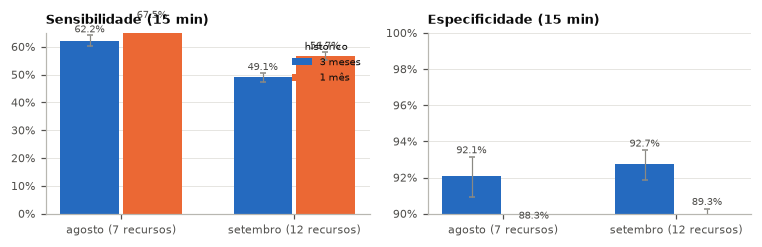

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.3))
for ax, (tipo, titulo) in zip(axes, [("incidente", "Sensibilidade (15 min)"), ("controle", "Especificidade (15 min)")]):
    for j, h in enumerate(HISTORICOS):
        t_ = T_all[(PROPOSTO, 15, h)]
        for i, mes in enumerate(MESES_TESTE):
            g = t_[(t_["mes"] == mes) & (t_["tipo"] == tipo)]
            k, n = int(g["acerto_estado"].sum()), len(g)
            p_ = k / n
            lo, hi = wilson(k, n)
            x = i + (j - 0.5) * 0.36
            ax.bar(x, p_, width=0.34, color=[AZUL[4], CORES[1]][j], label=("3 meses" if h == "3m" else "1 mês") if i == 0 else None)
            ax.errorbar(x, p_, yerr=[[p_ - lo], [hi - p_]], color=TXT3, capsize=2, lw=0.8)
            ax.text(x, hi + (0.01 if tipo == "incidente" else 0.002), f"{p_:.1%}", ha="center", fontsize=6.3, color=TXT2)
    ax.set_xticks(range(len(MESES_TESTE)))
    ax.set_xticklabels(["agosto (7 recursos)", "setembro (12 recursos)"])
    ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0))
    ax.set_title(titulo, loc="left")
    ax.grid(axis="x", visible=False)
    if tipo == "controle":
        ax.set_ylim(0.9, 1.0)
    else:
        ax.set_ylim(0, 0.65)
axes[0].legend(title="histórico", loc="upper right", fontsize=6.5, title_fontsize=6.5)
fig.tight_layout()
salvar(fig, "fig_historico")
plt.show()

## Resultado por mês de teste (proposto, 3 meses, 15 min)
Agosto tem 7 recursos; setembro tem os 12. Para comparar o mesmo conjunto de recursos, também se mostra setembro só com os 7 de agosto.

In [19]:
t = T[(PROPOSTO, 15)]
rec_ago = set(t.loc[t["mes"] == "ago", "recurso"])
grupos = {"agosto (7 recursos)": t["mes"] == "ago", "setembro (12 recursos)": t["mes"] == "set",
          "setembro (mesmos 7)": (t["mes"] == "set") & t["recurso"].isin(rec_ago)}
por_mes = []
for nome_g, m in grupos.items():
    g = t[m]
    i, c = inc(g), ctl(g)
    ima = i[i["intensidade"].isin(["media", "alta"])]
    det = i[i["residual"]]
    por_mes.append(dict(grupo=nome_g, sensibilidade=fmt_ic(int(i["residual"].sum()), len(i)),
                        sens_media_alta=fmt_ic(int(ima["residual"].sum()), len(ima)),
                        especificidade=fmt_ic(int((~c["residual"]).sum()), len(c)),
                        acuracia_indicador=fmt_ic(int((det["indicador"] == det["esperado"]).sum()), len(det))))
por_mes = pd.DataFrame(por_mes)
por_mes

,grupo,sensibilidade,sens_media_alta,especificidade,acuracia_indicador
0,agosto (7 recursos),62.2% [60.2%; 64.2%],67.5% [65.0%; 69.9%],92.1% [90.9%; 93.1%],93.5% [92.0%; 94.6%]
1,setembro (12 recursos),49.1% [47.5%; 50.7%],53.5% [51.5%; 55.5%],92.7% [91.9%; 93.5%],88.2% [86.6%; 89.6%]
2,setembro (mesmos 7),65.4% [63.4%; 67.3%],71.5% [69.1%; 73.8%],92.5% [91.3%; 93.5%],92.5% [91.0%; 93.7%]


## Latência ×10: justificativa e efeito
Distribuição, no histórico, da razão entre o p95 horário e a mediana do seu contexto (recurso × tipo de dia × hora).

In [20]:
j1 = recortar(pd.read_parquet(RESULTADOS / "02_janelas_60min.parquet"), TREINO)
med_ctx = j1.groupby(["recurso", "tipo_dia", "hora"])["lat_p95"].transform("median")
razao_lat = (j1["lat_p95"] / med_ctx).dropna()
lat_real = pd.Series({"p99": razao_lat.quantile(0.99), "p99,9": razao_lat.quantile(0.999), "máximo": razao_lat.max(),
                      "horas ≥ 4×": (razao_lat >= 4).mean(), "horas ≥ 10×": (razao_lat >= 10).mean()})
display(lat_real.round(4))
sens_lat = inc(t)[inc(t)["motivo"] == "latencia"].groupby("intensidade")["residual"].agg(["mean", "size"]).reindex(INTENSIDADES)
sens_lat["IC 95%"] = [fmt_ic(int(round(m * n)), int(n)) for m, n in sens_lat[["mean", "size"]].to_numpy()]
sens_lat

p99             8.7627
p99,9          25.2474
máximo         67.5333
horas ≥ 4×      0.0231
horas ≥ 10×     0.0078
dtype: float64

,mean,size,IC 95%
intensidade,,,
baixa,0.134211,380,13.4% [10.4%; 17.2%]
media,0.297368,380,29.7% [25.4%; 34.5%]
alta,0.578947,380,57.9% [52.9%; 62.8%]
muito_alta,0.786842,380,78.7% [74.3%; 82.5%]


## Critérios de sucesso

In [21]:
r15 = resumo[(resumo["metodo"] == PROPOSTO) & (resumo["L"] == 15)].iloc[0]
acc15 = acc_ind[15]
p_min = mc[(mc["L"] == 15)]
perde = ((p_min["so_baseline_acerta"] > p_min["so_proposto_acerta"]) & (p_min["p"] < 0.05)).any()
criterios = pd.DataFrame([
    ("Controles com saída Normal ≥ 95%", f"{r15['espec']:.1%}", r15["espec"] >= 0.95),
    ("Sensibilidade 15 min, intensidade média/alta ≥ 70%", f"{r15['sens_ma']:.1%}", r15["sens_ma"] >= 0.70),
    ("Acurácia do indicador ≥ 90%", f"{acc15.mean():.1%}", acc15.mean() >= 0.90),
    ("Início real na zona estimada ≥ 70%", f"{ti['acerto_inicio'].mean():.1%}", ti["acerto_inicio"].mean() >= 0.70),
    ("Sem perda significativa para baselines (McNemar)", "sim" if not perde else "não", not perde),
], columns=["critério", "resultado", "atendido"])
criterios

,critério,resultado,atendido
0,Controles com saída Normal ≥ 95%,92.5%,False
1,"Sensibilidade 15 min, intensidade média/alta ≥...",58.6%,False
2,Acurácia do indicador ≥ 90%,90.4%,True
3,Início real na zona estimada ≥ 70%,89.0%,True
4,Sem perda significativa para baselines (McNemar),não,False


## Comparação por motivo e uso dos múltiplos regimes
Sensibilidade por motivo em cada método (15 min, 3 meses) e, nos controles, em qual regime o período normal se enquadrou.

In [22]:
sm_met = pd.concat({n: inc(T[(n, L_PRINCIPAL)]).groupby("motivo")["residual"].mean() for n in METODOS}, axis=1)
sm_met.index = sm_met.index.map(NOMES_MOTIVO)
sm_met.loc["especificidade"] = [(~ctl(T[(n, L_PRINCIPAL)])["residual"]).mean() for n in METODOS]
display(sm_met.round(3))

p15c = P[(P["periodo"] == "L") & (P["id_periodo"] == L_PRINCIPAL)].set_index("cenario")
p15c = p15c.join(cenarios.set_index("cenario")[["tipo", "mes"]])
uso = []
for mes, g in p15c.groupby("mes"):
    cal = calib[(PROPOSTO, L_PRINCIPAL, mes, HIST_PRINCIPAL)]
    mod = cal["modelo"]
    _, reg = mod._escolha(g, cal["limite"])
    res, _, _ = decidir(g, cal)
    for (c, row), j, r_ in zip(g.iterrows(), reg, res):
        mr = mod.rec.get(row["recurso"])
        if mr is None or j < 0:
            continue
        td, h = (0 if row["tipo_dia"] == "util" else 1), int(row["hora"])
        fr = mr["frac"].to_numpy().reshape(2, 24, mr["k"])[td, h]
        dominante = int(np.nanargmax(fr)) if np.isfinite(fr).any() else -1
        uso.append(dict(cenario=c, tipo=row["tipo"], mes=mes, residual=bool(r_), n_adm=int(mr["adm"][td, h].sum()),
                        k=mr["k"], dominante=bool(j == dominante)))
uso = pd.DataFrame(uso)
cn = uso[(uso["tipo"] == "controle") & ~uso["residual"]]
uso_resumo = dict(controles_normais=len(cn), frac_regime_nao_dominante=float((~cn["dominante"]).mean()),
                  regimes_admissiveis_medio=float(uso["n_adm"].mean()), frac_contextos_mais_de_um=float((uso["n_adm"] > 1).mean()))
uso_resumo

,Regimes normais (proposto),Perfil por contexto,Regimes sem contexto,z-score global,Semana anterior
motivo,,,,,
4xx de 1 consumidor,0.377,0.455,0.268,0.419,0.435
4xx generalizado,0.457,0.506,0.280,0.449,0.485
5xx de 1 consumidor,0.641,0.683,0.590,0.664,0.662
5xx generalizado,0.802,0.839,0.744,0.837,0.830
latência,0.449,0.605,0.347,0.574,0.551
especificidade,0.925,0.887,0.956,0.914,0.913


{'controles_normais': 5624,
 'frac_regime_nao_dominante': 0.47688477951635844,
 'regimes_admissiveis_medio': 2.6564942008719257,
 'frac_contextos_mais_de_um': 0.778563790408818}

In [23]:
P.to_parquet(RESULTADOS / "06_periodos.parquet", index=False)
pd.concat({f"{n} | {L} | {h}": t for (n, L, h), t in T_all.items()}).to_parquet(RESULTADOS / "06_decisoes.parquet")
hist_tab.to_csv(RESULTADOS / "06_historico_3m_1m.csv", index=False)
por_mes_hist.to_csv(RESULTADOS / "06_por_mes_historico.csv")
por_mes.to_csv(RESULTADOS / "06_por_mes.csv", index=False)
lat_real.to_csv(RESULTADOS / "06_latencia_real.csv")
sens_lat.to_csv(RESULTADOS / "06_sens_latencia.csv")
resumo.to_csv(RESULTADOS / "06_resumo.csv", index=False)
mc.to_csv(RESULTADOS / "06_mcnemar.csv", index=False)
sm.to_csv(RESULTADOS / "06_sens_motivo.csv")
sa.to_csv(RESULTADOS / "06_sens_atraso.csv")
sa_ma.to_csv(RESULTADOS / "06_sens_atraso_media_alta.csv")
conf.to_csv(RESULTADOS / "06_confusao_indicador.csv")
acc_ind_tab.to_csv(RESULTADOS / "06_acuracia_indicador.csv")
tab_abr.to_csv(RESULTADOS / "06_abrangencia.csv")
acerto_inicio.to_csv(RESULTADOS / "06_inicio.csv")
zonas.to_csv(RESULTADOS / "06_zonas_inicio.csv")
por_rec.to_csv(RESULTADOS / "06_por_recurso.csv")
criterios.to_csv(RESULTADOS / "06_criterios.csv", index=False)
curva.to_csv(RESULTADOS / "06_curva_operacao.csv", index=False)
salvar_json(dict(incidentes_sem_trafego=len(sem_traf), acuracia_abrangencia=float(acc_abr.mean()), n_abrangencia=int(len(acc_abr)),
                 acerto_inicio=float(ti["acerto_inicio"].mean()), n_inicio=int(len(ti)),
                 cenario_exemplo=int(c_ex)), "06_resumo.json")
sm_met.to_csv(RESULTADOS / "06_sens_motivo_metodos.csv")
salvar_json(uso_resumo, "06_uso_regimes.json")
print("resultados salvos")

resultados salvos
